# Exercício 06 — Atenuação de ruído sísmico com CSC

**Disciplina:** PPGEEC2327 — Tópicos Especiais em Processamento Inteligente da Informação  
**Autor:** Lucas Torres Marques  
**Laboratório:** [Convolutional Sparse Coding for Noise Attenuation of Seismic Data — Zhaolun Liu](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Sparse/Chapter.Sparse2/lab.html)

Este notebook reúne a implementação, a execução e a interpretação dos experimentos de codificação esparsa convolucional (CSC). O núcleo numérico fica em `src/seismic_csc/csc.py`; o notebook apresenta os dados, os parâmetros, os filtros, as reconstruções e as respostas às perguntas do laboratório.

**Perguntas:** como o tamanho e a quantidade dos filtros afetam a remoção de ruído? Como a penalização L1 controla a esparsidade e a perda de sinal? O que os filtros CSC têm em comum com os da primeira camada de uma CNN?

As anotações quantitativas em Markdown descrevem a execução de referência com sementes **2026** (treino) e **2027** (ruído). As tabelas, figuras e os comentários calculados nas células acompanham a configuração da execução atual. Caso os parâmetros sejam alterados, compare as novas saídas com as anotações de referência.

## 1. Formulação e estratégia numérica

A imagem observada é representada por uma soma de convoluções entre filtros locais $d_k$ e mapas de coeficientes $z_k$. O problema de treinamento é

$$
\min_{d,z}\; \frac{\lambda_{\mathrm{res}}}{2}
\left\|x-M\left(\sum_{k=1}^{K}d_k*z_k\right)\right\|_2^2
+\beta\sum_{k=1}^{K}\|z_k\|_1,
\qquad \|d_k\|_2\leq 1.
$$

A máscara $M$ seleciona a região observada do domínio estendido. A restrição de norma limita a escala dos filtros. O treinamento alterna a atualização de $d$ e $z$; os subproblemas usam ADMM, com convoluções e sistemas lineares resolvidos no domínio da frequência. Na remoção de ruído, o dicionário fica fixo e apenas $z$ é estimado.

A conversão conserva os parâmetros, a projeção dos filtros e a regra de restauração do MATLAB. As operações usam `float64` e indicam os eixos espaciais `(0, 1)` nas FFTs. As diferenças de indexação, de bordas e de retorno do ADMM estão descritas em [notas de implementação no README](README.md#pontos-importantes-da-conversão).

## 2. Ambiente e configuração

O código identifica `exercise06/` tanto quando o kernel inicia nesta pasta quanto quando inicia na raiz do repositório. O ambiente Conda está em `../conda.yaml`. A execução usa CPU e não requer MATLAB ou PyTorch.

A configuração abaixo conserva 80 iterações externas, 10 atualizações internas e tolerância `1e-3`. O número máximo de iterações é um orçamento, não uma garantia de convergência. Uma nova execução atualiza `original/results/main/`; os materiais originais são apenas lidos.

In [59]:
import os
import sys
from pathlib import Path

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for candidate in candidates for p in (candidate, candidate / "exercise06")
             if (p / "src/seismic_csc").is_dir() and (p / "original").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não foi possível localizar exercise06/.")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "original/.cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))

import json
import platform
from dataclasses import asdict
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from seismic_csc.csc import snr_db, convolution_components
import importlib
from seismic_csc import experiments as csc_experiments, plotting as csc_plotting
importlib.reload(csc_experiments)
importlib.reload(csc_plotting)
from seismic_csc.experiments import (
    ExperimentConfig, ExperimentSuite, SIZES, COUNTS, BETAS,
    size_name, count_name, run_count_sweep, run_beta_sweep,
)
from seismic_csc.plotting import (
    plot_gathers, plot_preprocessing, plot_filters, plot_training,
    plot_decomposition, plot_denoising, plot_comparison, plot_sweeps,
    plot_cnn_comparison,
)

CONFIG = ExperimentConfig()
OUTPUT = ROOT / "original/results/main"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 100})
pd.set_option("display.max_columns", 20)

def show(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150)
    display(fig)
    plt.close(fig)

def report(rows):
    columns = ["experiment", "snr_after_db", "snr_gain_db", "mse",
               "active_fraction", "denoise_seconds", "iterations", "stop_reason"]
    display(rows[columns].round(4).reset_index(drop=True))

display(pd.Series(asdict(CONFIG), name="Valor").to_frame())
print("Python", platform.python_version(), "| NumPy", np.__version__,
      "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)

,Valor
training_seed,2026.000
noise_seed,2027.000
noise_sigma,0.300
training_beta,1.000
denoising_beta,0.500
lambda_residual,1.000
train_max_iter,80.000
denoise_max_iter,80.000
inner_iter,10.000
tol,0.001


Python 3.12.16 | NumPy 2.5.4 | SciPy 1.18.1 | Matplotlib 3.11.2


## 3. Dados e pré-processamento

O pacote oficial é verificado por SHA-256 antes da leitura. Se ainda não estiver em `original/csc_code.zip`, a rotina realiza o download. Os MAT são lidos em memória, sem alterar a extração MATLAB.

`b.mat` contém cinco CSGs de dimensão `181 × 100`. O treinamento usa `b[:100, :, 0]` e a avaliação usa `b[:100, :, 1]`, seguindo a indexação dos scripts originais. Cada recorte passa por normalização de contraste local com janela gaussiana `21 × 21`, desvio padrão `4,773`, e remoção da média global.

O ruído gaussiano de desvio padrão `0,3` é acrescentado **depois** desse pré-processamento. Assim, a referência de SNR é o segundo CSG normalizado e centralizado. Os eixos usam índices de amostra e traço, pois o MAT não fornece coordenadas físicas.

,Dado,Forma,Uso
0,Todos os CSGs,"(181, 100, 5)",Inspeção
1,CSG 1 recortado,"(100, 100)",Treinamento
2,CSG 2 recortado,"(100, 100)",Avaliação com ruído sintético


SHA-256 do ZIP: fe5bd09472bd0f2d334450be19fe1f8ce56864b536e3a5d26eaa8fe1fd3fd44f
SNR de entrada: 7.075485 dB


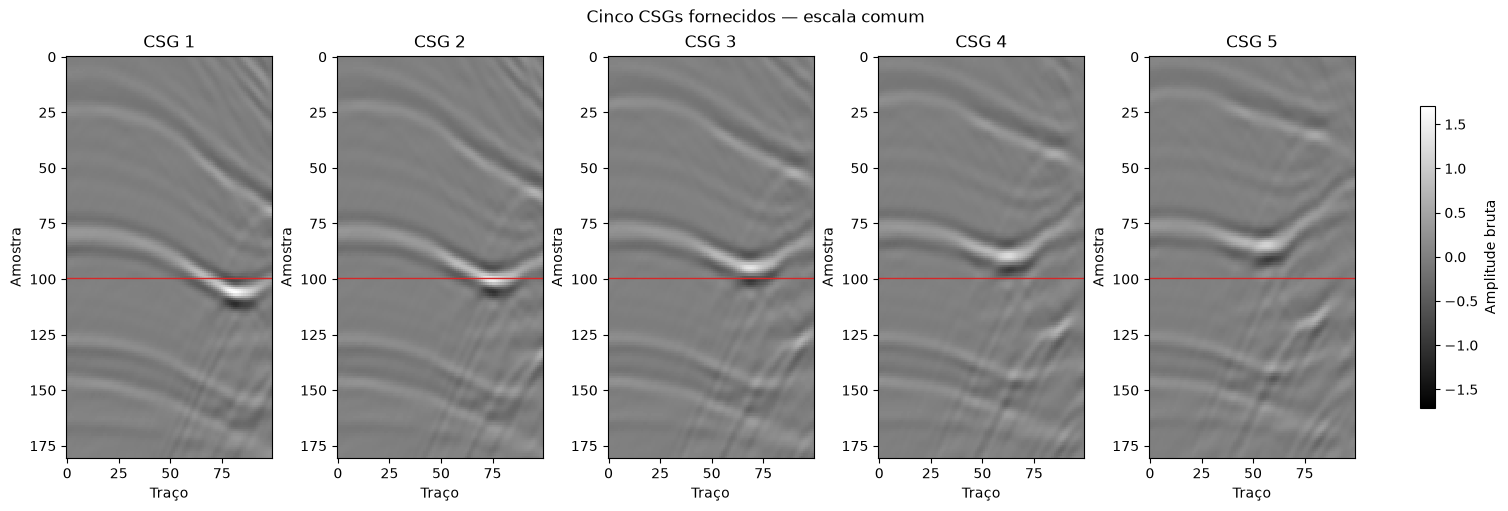

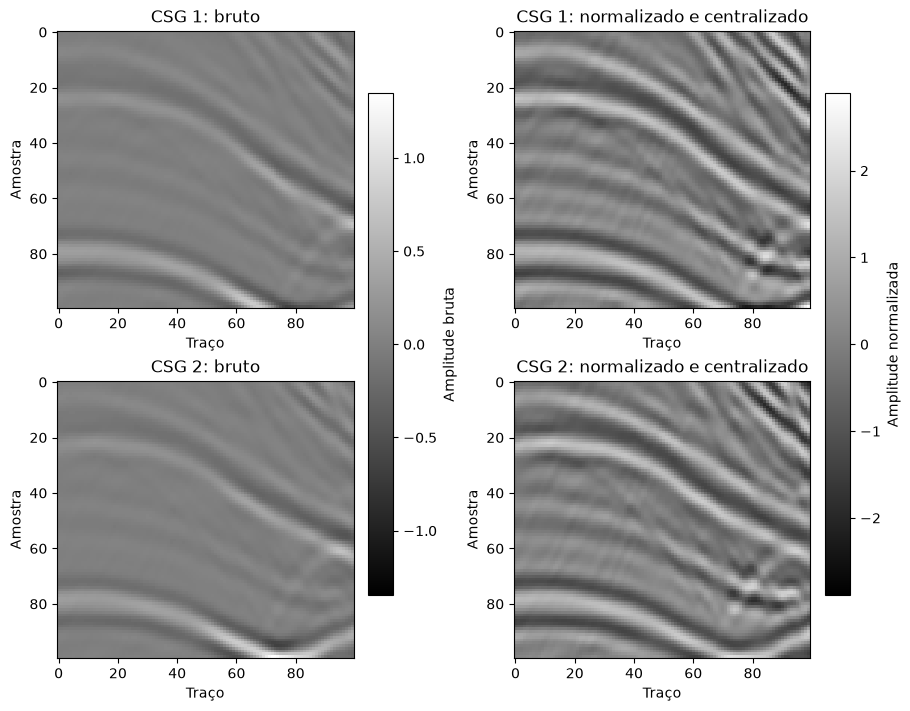

In [60]:
suite = ExperimentSuite(ROOT, CONFIG, OUTPUT)
display(pd.DataFrame([
    {"Dado": "Todos os CSGs", "Forma": str(suite.gathers.shape), "Uso": "Inspeção"},
    {"Dado": "CSG 1 recortado", "Forma": str(suite.train.shape), "Uso": "Treinamento"},
    {"Dado": "CSG 2 recortado", "Forma": str(suite.clean.shape), "Uso": "Avaliação com ruído sintético"},
]))
print("SHA-256 do ZIP:", suite.metadata["archive_sha256"])
print("SNR de entrada:", round(snr_db(suite.clean, suite.noisy), 6), "dB")
show(plot_gathers(suite.gathers), "gathers")
show(plot_preprocessing(suite), "preprocessing")

### Leitura dos dados

O recorte preserva os eventos inclinados e curvos na parte superior dos registros. A normalização local modifica as amplitudes e aumenta a visibilidade de eventos mais fracos. Como esse procedimento é aplicado antes de gerar o ruído, o experimento mede a recuperação do dado normalizado; não demonstra recuperação das amplitudes físicas originais.

Embora existam cinco CSGs no pacote, esta reprodução usa somente os dois escolhidos pelo MATLAB. Os demais aparecem na inspeção, sem participar do ajuste ou da seleção de parâmetros.

## 4. Verificação da conversão e dicionário MATLAB

Durante o desenvolvimento, foram executadas verificações independentes de convolução, sistemas lineares complexos, normalização de borda, projeção, máscara, repetibilidade e reconstrução de um sinal sintético suave.

O arquivo `filters.mat` contém três filtros de `21 × 11`. Eles permitem comparar a reconstrução com um dicionário já fornecido. O algoritmo retorna um iterado ADMM que pode ainda violar ligeiramente a restrição de norma; os filtros originais não serão renormalizados automaticamente.

Normas dos filtros MATLAB: [1.01041626 1.01041324 1.02045886]
Objetivo armazenado no MAT: 576.1575174414269


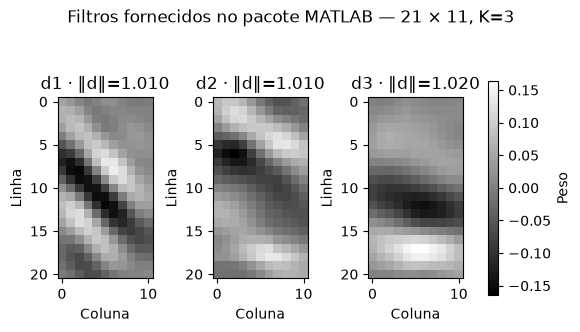

In [61]:
print("Normas dos filtros MATLAB:", np.linalg.norm(suite.matlab_reference["d"], axis=(0, 1)))
print("Objetivo armazenado no MAT:", float(suite.matlab_reference["obj"].item()))
show(plot_filters(suite.matlab_reference["d"], "Filtros fornecidos no pacote MATLAB"), "matlab_filters")

### O que a validação estabelece

As verificações confirmam as convenções espaciais e as soluções dos sistemas lineares usados pelo código Python. Não executamos MATLAB neste experimento; portanto, não há uma comparação completa entre execuções com estados iniciais idênticos nas duas linguagens. O arquivo de referência também não registra a semente usada originalmente. A equivalência pretendida é do procedimento numérico, e não de um dicionário específico obtido por inicialização aleatória.

## 5. Treinamento de referência

Usamos três filtros de `21 × 11`, `beta_train = 1`, `lambda_residual = 1` e a semente de treinamento 2026. A inicialização mantém filtros e coeficientes gaussianos, como no MATLAB. O código registra os objetivos após atualizar D e Z, as mudanças relativas e o motivo de parada. Se nenhuma das duas direções melhorar o critério do código original, restaura os iterados anteriores.

Treino reference: (21, 11), K=3, 80 iterações aceitas, max_iter, 3.86 s


,iteration,objective_d,objective_z,relative_d,relative_z,elapsed_seconds
76,76,50.495286,49.969055,0.018161,0.031614,3.656199
77,77,50.468126,49.264622,0.017915,0.031847,3.704806
78,78,49.507789,48.771052,0.018828,0.030381,3.752750
79,79,49.099595,48.556715,0.017081,0.029197,3.804348
80,80,49.243844,48.026594,0.014633,0.027795,3.857441


Iterações aceitas: 80 | tentadas: 80 | parada: max_iter
Normas: [0.99981656 0.99993548 0.99970399]


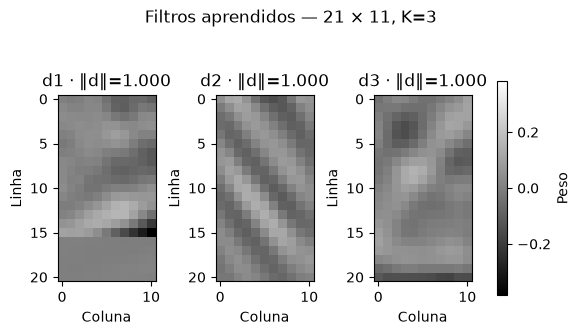

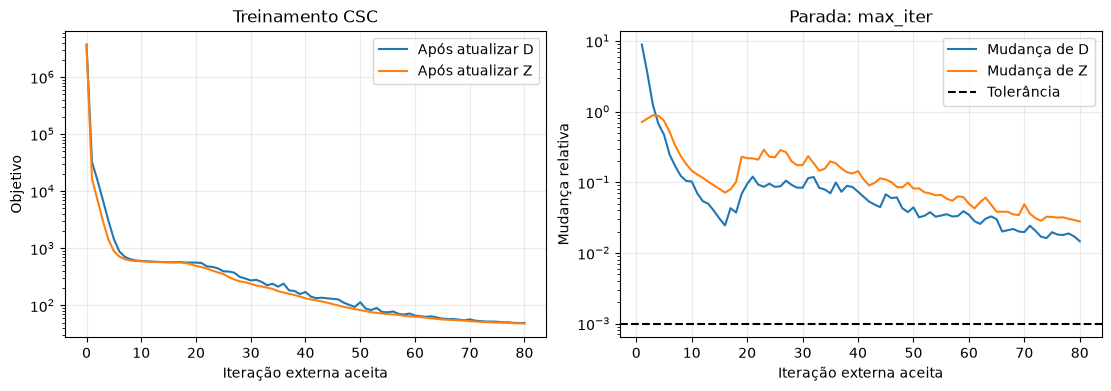

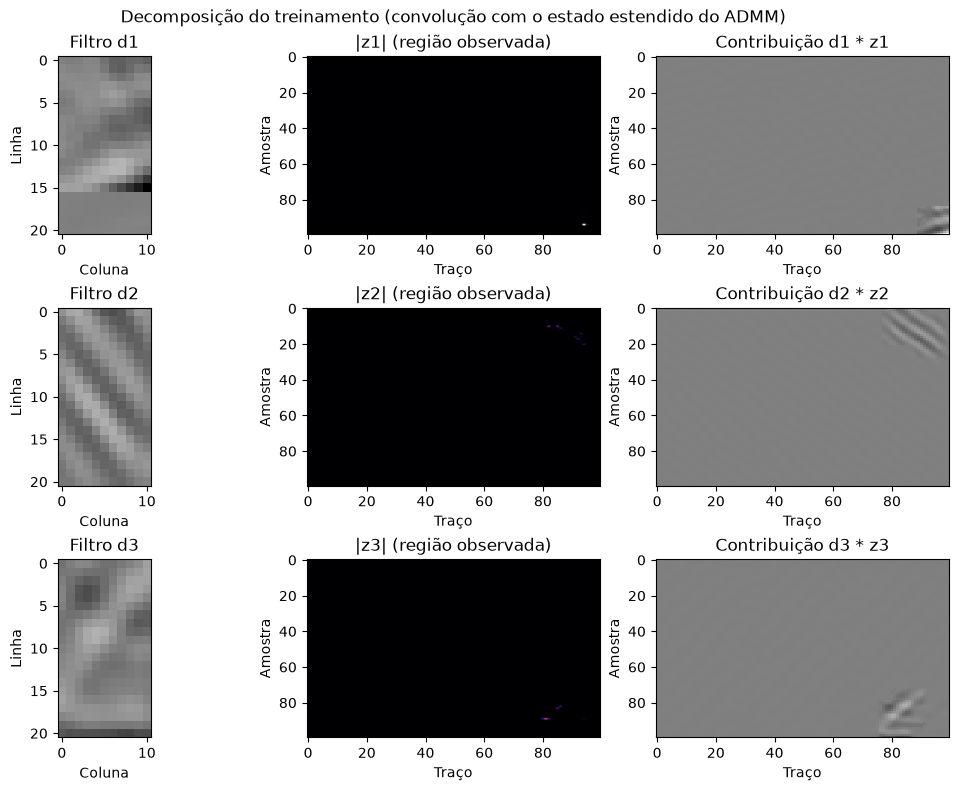

In [62]:
reference_training = suite.train_dictionary("reference")
display(pd.DataFrame(reference_training.history).tail().round(6))
print("Iterações aceitas:", reference_training.iterations,
      "| tentadas:", reference_training.attempted_iterations,
      "| parada:", reference_training.stop_reason)
print("Normas:", np.linalg.norm(reference_training.filters, axis=(0, 1)))
show(plot_filters(reference_training.filters), "reference_filters")
show(plot_training(reference_training, CONFIG.tol), "training_convergence")
show(plot_decomposition(reference_training, suite.train.shape), "training_decomposition")

### Análise do treinamento de referência

O treinamento realizou **80 iterações aceitas** e terminou pelo limite configurado, com objetivo final de aproximadamente **48.0266**. Esse motivo de parada não permite afirmar que a tolerância foi atingida, mas pela tendência de descida, nos ajuda a concluir que o treinamento ocorreu da maneira satisfatória. Os mapas de coeficientes e as contribuições mostram como diferentes filtros participam da representação dos eventos.

Os filtros aprendidos apresentam regiões positivas e negativas e padrões direcionais. Eles diferem dos filtros fornecidos, o que é compatível com um problema de treinamento não convexo e inicializações diferentes. Um objetivo de treinamento menor, por si só, não garante melhor reconstrução do segundo CSG.

A figura de decomposição usa o estado estendido de D retornado pelo ADMM para ser consistente com o objetivo do treinamento. Na remoção de ruído, usamos o suporte compacto retornado, seguindo a sequência MATLAB.

## 6. Remoção de ruído de referência

Com os filtros fixos, estimamos apenas os coeficientes do segundo CSG. A SNR usa a razão entre a energia do sinal de referência e a energia do erro:

$$\mathrm{SNR}(x,\hat{x})=10\log_{10}\frac{\sum x^2}{\sum(\hat{x}-x)^2}.$$

A comparação adicional usa os filtros de `filters.mat` sobre **a mesma imagem ruidosa**. Ela descreve dois dicionários concretos, sem isolar o efeito da linguagem ou da semente.

Denoising reference: beta=0.5, SNR=10.087 dB, 0.20 s
Denoising matlab_supplied: beta=0.5, SNR=15.142 dB, 0.20 s


,experiment,snr_after_db,snr_gain_db,mse,active_fraction,denoise_seconds,iterations,stop_reason
0,reference,10.0869,3.0114,0.0453,0.1102,0.2033,80,max_iter
1,matlab_supplied,15.1423,8.0668,0.0142,0.0592,0.1954,80,max_iter


Erro máximo na soma das contribuições: 9.992e-16


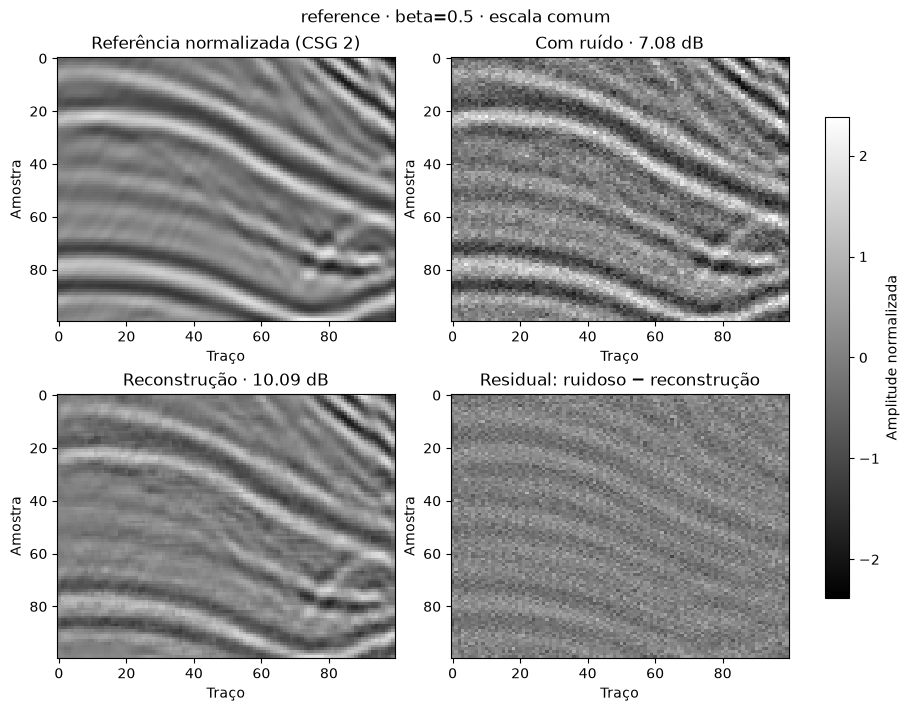

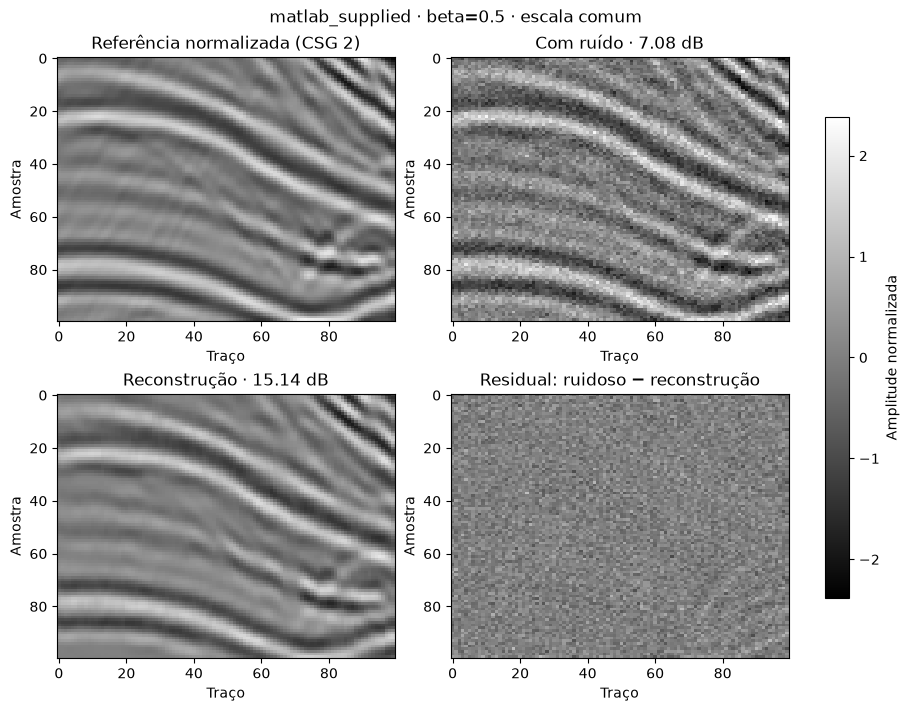

Na execução atual, a referência Python passou de **7.075 dB** para **10.087 dB**.

In [63]:
reference_reconstruction = suite.denoise("reference")
matlab_reconstruction = suite.denoise("matlab_supplied", "matlab_supplied")
report(suite.summary)
parts = convolution_components(reference_training.filters, reference_reconstruction.coefficients, suite.clean.shape)
error = np.max(np.abs(parts.sum(axis=2) - reference_reconstruction.reconstruction))
assert error < 1e-11
print(f"Erro máximo na soma das contribuições: {error:.3e}")
show(plot_denoising(suite), "reference_denoising")
show(plot_denoising(suite, "matlab_supplied"), "matlab_denoising")
display(Markdown(f"Na execução atual, a referência Python passou de **{suite.metrics['reference']['snr_before_db']:.3f} dB** para **{suite.metrics['reference']['snr_after_db']:.3f} dB**."))

### Resultado e interpretação

Na referência salva, a SNR passou de **7,08 dB para 10,09 dB**, com ganho de **3,01 dB**. Os filtros fornecidos produziram **15,14 dB** no mesmo dado ruidoso. Isso mostra que a solução aprendida e o histórico do dicionário influenciam a qualidade da reconstrução; a diferença não mede uma superioridade de MATLAB sobre Python.

As duas reconstruções reduzem a textura aleatória da entrada. Na referência Python, o residual também contém estruturas relacionadas aos eventos sísmicos, indicando perda de sinal junto com a remoção de ruído. Todas as imagens deste bloco usam uma mesma escala de amplitude, para não ocultar essa atenuação por normalização gráfica independente.

## 7. Questão 1a — Tamanho dos filtros

Variamos o tamanho entre `(11, 7)`, `(21, 11)` e `(31, 15)`, mantendo `K = 3`, as penalizações, o recorte de treino e o ruído. Cada tamanho exige um novo treinamento. A configuração central reutiliza o dicionário de referência em memória.

A semente é a mesma, mas matrizes de formas diferentes recebem estados iniciais diferentes. Assim, o experimento documenta o efeito observado dessas configurações sob um orçamento fixo; não estima uma média sobre várias inicializações.

Treino size_11x7: (11, 7), K=3, 80 iterações aceitas, max_iter, 4.64 s
Denoising size_11x7: beta=0.5, SNR=14.293 dB, 0.24 s
Treino size_31x15: (31, 15), K=3, 80 iterações aceitas, max_iter, 4.93 s
Denoising size_31x15: beta=0.5, SNR=11.706 dB, 0.24 s


,experiment,snr_after_db,snr_gain_db,mse,active_fraction,denoise_seconds,iterations,stop_reason
0,size_11x7,14.2925,7.2170,0.0172,0.0881,0.2436,80,max_iter
1,reference,10.0869,3.0114,0.0453,0.1102,0.2033,80,max_iter
2,size_31x15,11.7060,4.6305,0.0312,0.0907,0.2417,80,max_iter


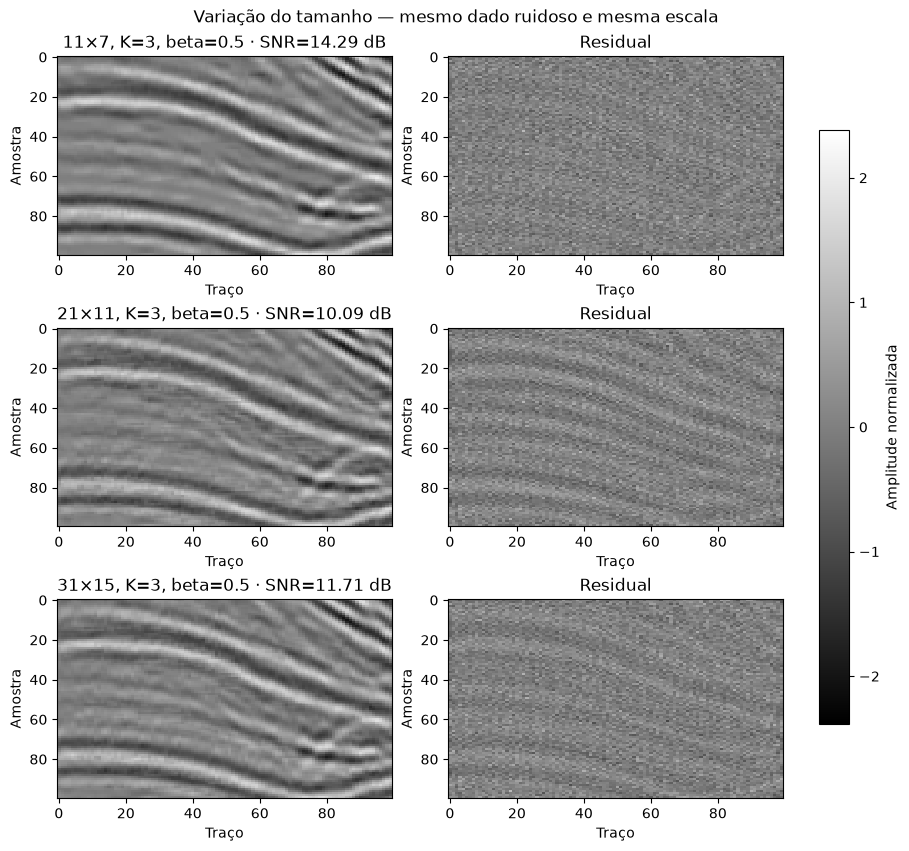

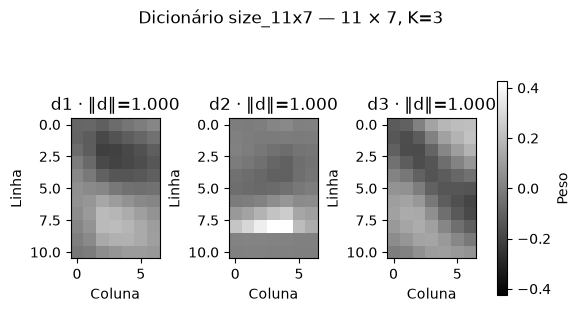

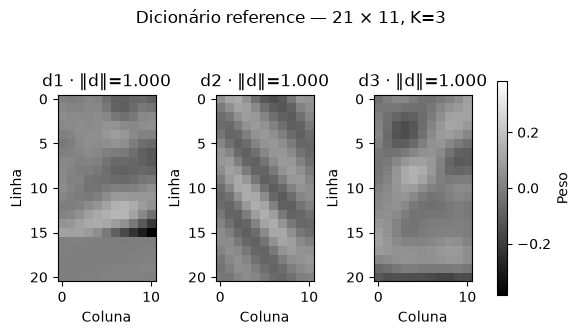

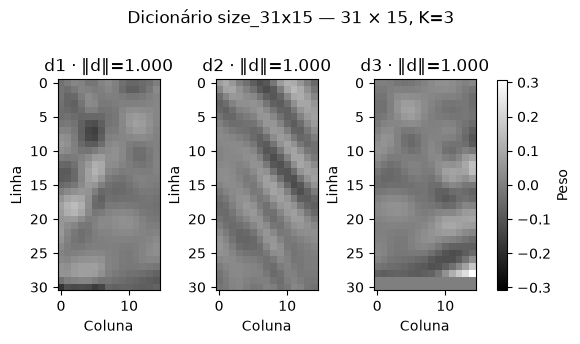

In [64]:
for shape in SIZES:
    name = size_name(shape)
    if name != "reference":
        suite.train_dictionary(name, shape, 3)
        suite.denoise(name, name)
size_rows = suite.summary.set_index("experiment").loc[[size_name(s) for s in SIZES]].reset_index()
report(size_rows)
show(plot_comparison(suite, [size_name(s) for s in SIZES], "Variação do tamanho"), "size_comparison")
for shape in SIZES:
    name = size_name(shape)
    show(plot_filters(suite.trainings[name].filters, f"Dicionário {name}"), f"filters_{name}")

### Resposta sobre o tamanho

As SNRs foram **14,29 dB** com `11 × 7`, **10,09 dB** com `21 × 11` e **11,71 dB** com `31 × 15`. O menor filtro foi o melhor nesta série; aumentar o suporte não gerou uma melhora monotônica.

Filtros maiores podem representar eventos mais extensos, mas aumentam a quantidade de parâmetros e o domínio de otimização. As diferenças residuais mostram que a preservação dos eventos depende da solução aprendida, além do tamanho do suporte. O resultado é específico deste recorte, desta semente e do limite de iterações; não estabelece que filtros pequenos sejam sempre preferíveis.

## 8. Questão 1a — Quantidade de filtros

Vamos manter o suporte `21 × 11` e variar `K = 1, 3, 6, 9, 12`. Aumentar K oferece mais componentes para representar estruturas, com maior consumo de memória e custo por atualização. A tabela inclui a fração de coeficientes ativos, definida por `|z| > 10⁻³ max(|z|)` em todo o domínio estendido de cada resultado.

Essa fração é um diagnóstico dependente do limiar e do número de coeficientes. Ela não equivale à quantidade de zeros exatos de uma solução totalmente convergida.

Treino count_1: (21, 11), K=1, 16 iterações aceitas, no_progress_rollback, 0.28 s
Denoising count_1: beta=0.5, SNR=3.536 dB, 0.07 s
Treino count_6: (21, 11), K=6, 69 iterações aceitas, no_progress_rollback, 5.02 s
Denoising count_6: beta=0.5, SNR=12.989 dB, 0.28 s
Treino count_9: (21, 11), K=9, 76 iterações aceitas, no_progress_rollback, 7.78 s
Denoising count_9: beta=0.5, SNR=13.492 dB, 0.36 s
Treino count_12: (21, 11), K=12, 20 iterações aceitas, no_progress_rollback, 2.69 s
Denoising count_12: beta=0.5, SNR=15.924 dB, 0.44 s


,experiment,snr_after_db,snr_gain_db,mse,active_fraction,denoise_seconds,iterations,stop_reason
0,count_1,3.5355,-3.5399,0.2049,0.2564,0.0670,80,max_iter
1,reference,10.0869,3.0114,0.0453,0.1102,0.2033,80,max_iter
2,count_6,12.9887,5.9132,0.0232,0.0496,0.2778,80,max_iter
3,count_9,13.4919,6.4164,0.0207,0.0327,0.3645,80,max_iter
4,count_12,15.9245,8.8490,0.0118,0.0176,0.4403,80,max_iter


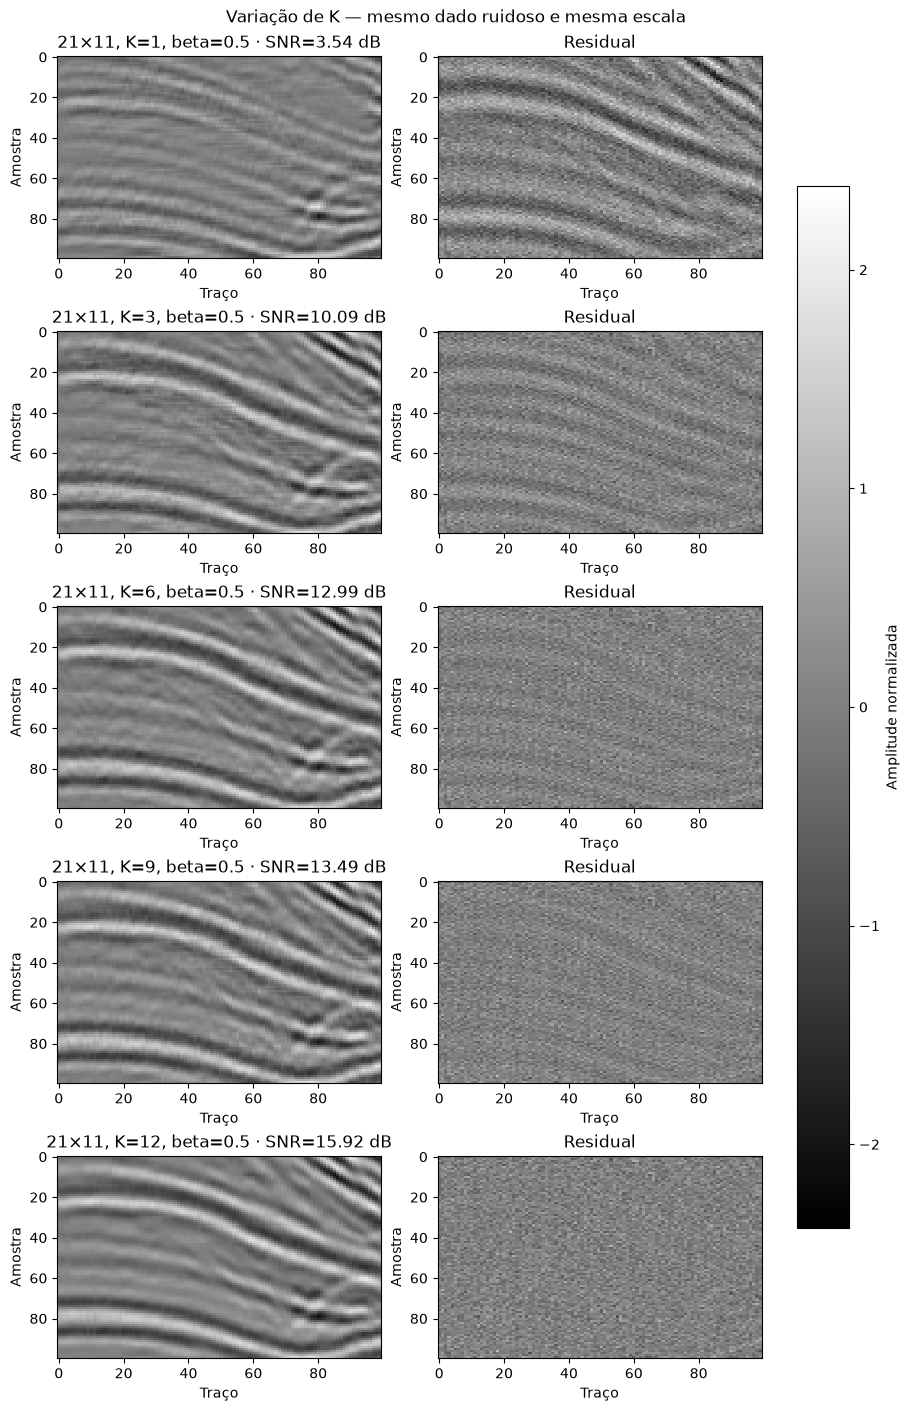

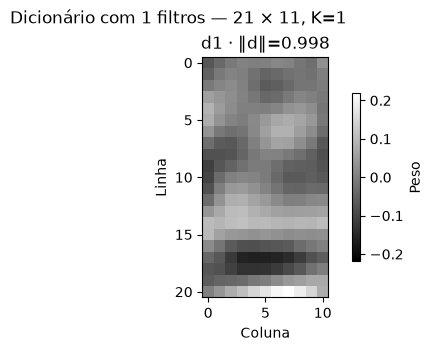

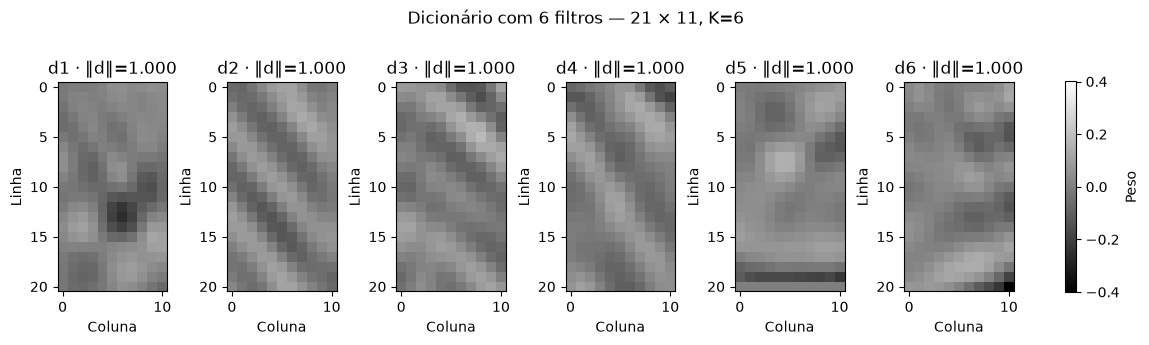

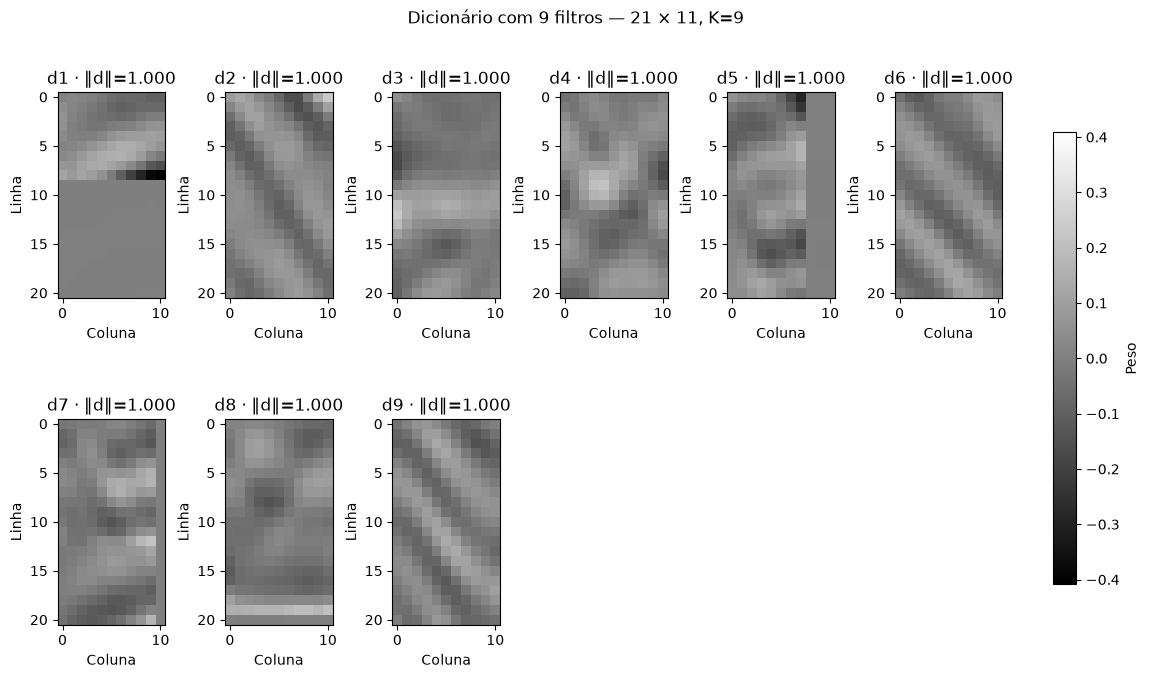

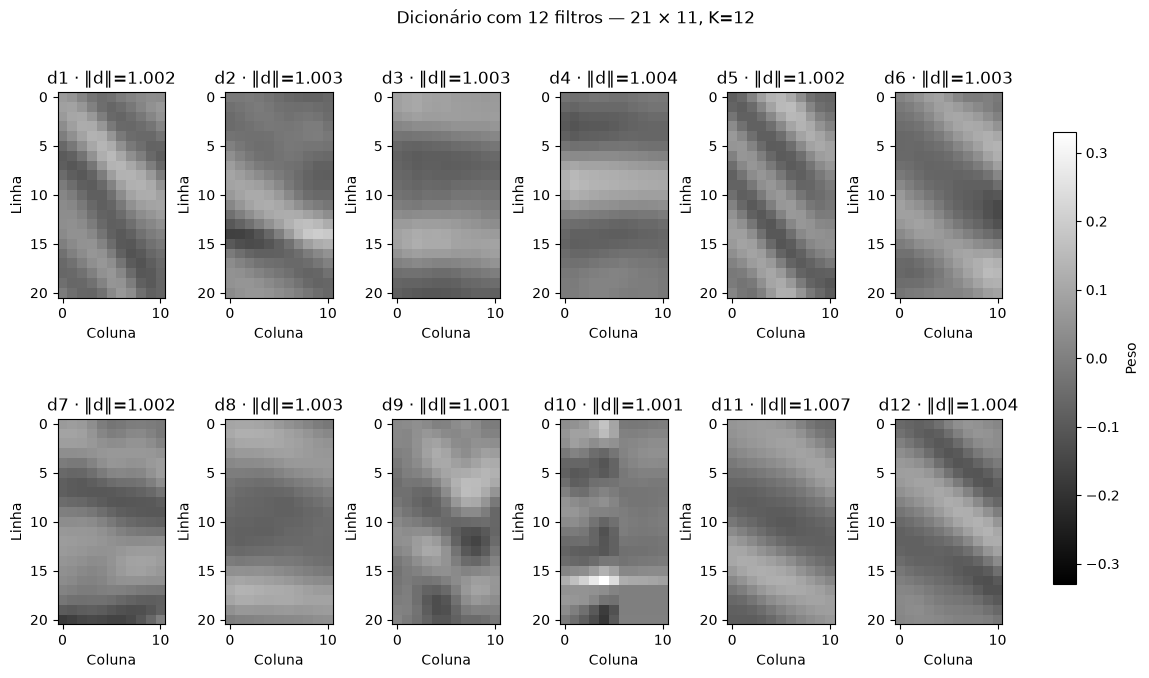

In [65]:
count_ids = run_count_sweep(suite)
count_rows = suite.summary.set_index("experiment").loc[count_ids].reset_index()
report(count_rows)
show(plot_comparison(suite, count_ids, "Variação de K"), "count_comparison")
for count in COUNTS:
    name = count_name(count)
    if count != 3:
        show(plot_filters(suite.trainings[name].filters, f"Dicionário com {count} filtros"), f"filters_{name}")

### Resposta sobre a quantidade

Com `K = 1`, a SNR foi **3,54 dB**, inferior aos 7,08 dB da entrada ruidosa. Com três e seis filtros, os valores foram **10,09 dB** e **12,99 dB**. Nesta execução, um único filtro não ofereceu uma representação adequada para reconstruir os eventos do segundo CSG, e seis filtros superaram a referência de três.

Os treinamentos de `K = 1` e `K = 6` encerraram pela regra de ausência de progresso, com restauração do estado anterior. Isso explica parte da diferença entre seus números de iterações e tempos. O custo total não pode ser interpretado apenas como função de K, pois os critérios de parada também influenciam o tempo medido.

## 9. Questão 1b — Penalização L1 na remoção de ruído

Fixamos o dicionário selecionado automaticamente pela maior SNR da seção 8 e o dado ruidoso e variamos $\beta$ entre `0,1`, `0,25`, `0,5`, `1`, `2` e `5`. O treinamento não é repetido nesta série. Cada reconstrução parte de coeficientes e variáveis duais nulos, com o mesmo limite de 80 iterações.

Aumentar beta pressiona os coeficientes em direção a zero. O objetivo contém tanto o ajuste ao dado ruidoso quanto a penalização de esparsidade; objetivos calculados com betas diferentes não são diretamente comparáveis como critério único de qualidade.

Denoising beta_0p1: beta=0.1, SNR=12.722 dB, 0.46 s
Denoising beta_0p25: beta=0.25, SNR=15.238 dB, 0.46 s
Denoising beta_1: beta=1, SNR=14.105 dB, 0.46 s
Denoising beta_2: beta=2, SNR=10.386 dB, 0.45 s
Denoising beta_5: beta=5, SNR=4.771 dB, 0.44 s


,beta,snr_after_db,snr_gain_db,mse,active_fraction,removed_energy_fraction,iterations
0,0.10,12.72204,5.64655,0.02471,0.03485,0.09104,80
1,0.25,15.23808,8.16259,0.01384,0.02278,0.11901,80
2,0.50,15.92447,8.84898,0.01182,0.01760,0.14175,80
3,1.00,14.10522,7.02974,0.01797,0.01473,0.16948,80
4,2.00,10.38635,3.31087,0.04231,0.01223,0.22459,80
5,5.00,4.77127,-2.30421,0.15415,0.00659,0.43755,80


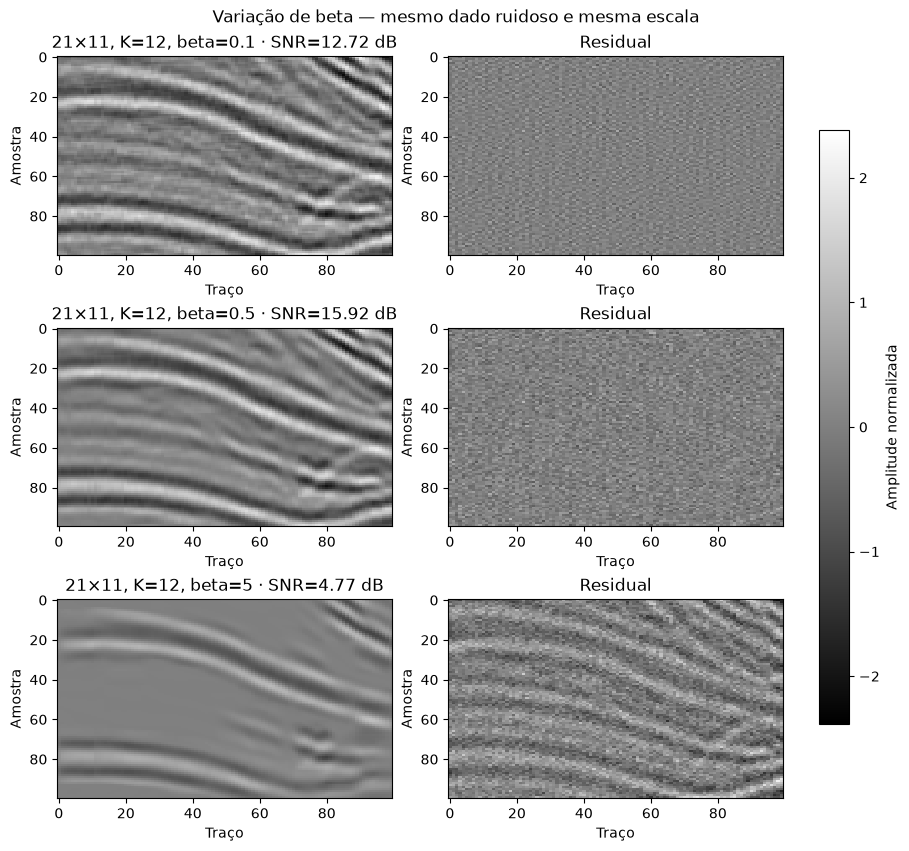

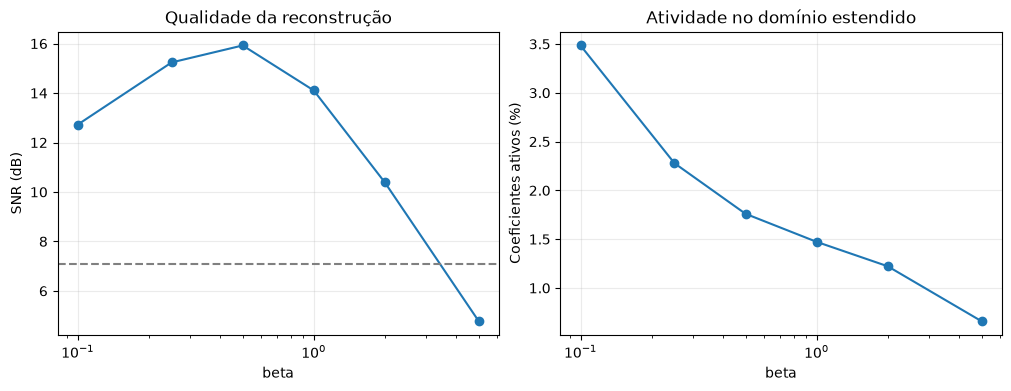

Melhor beta da grade atual: **0.5**, com SNR **15.924 dB**.

In [66]:
beta_ids = run_beta_sweep(suite)
beta_rows = suite.summary.set_index("experiment").loc[beta_ids].reset_index().sort_values("beta")
display(beta_rows[["beta", "snr_after_db", "snr_gain_db", "mse", "active_fraction", "removed_energy_fraction", "iterations"]].round(5))
show(plot_comparison(suite, [suite.beta_experiments[b] for b in (.1, .5, 5)], "Variação de beta"), "beta_comparison")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].semilogx(beta_rows.beta, beta_rows.snr_after_db, "o-")
axes[0].axhline(snr_db(suite.clean, suite.noisy), color="gray", linestyle="--")
axes[0].set(xlabel="beta", ylabel="SNR (dB)", title="Qualidade da reconstrução")
axes[1].semilogx(beta_rows.beta, beta_rows.active_fraction * 100, "o-")
axes[1].set(xlabel="beta", ylabel="Coeficientes ativos (%)", title="Atividade no domínio estendido")
for ax in axes:
    ax.grid(alpha=.25)
show(fig, "beta_metrics")
best_beta = beta_rows.loc[beta_rows.snr_after_db.idxmax()]
display(Markdown(f"Melhor beta da grade atual: **{best_beta.beta:g}**, com SNR **{best_beta.snr_after_db:.3f} dB**."))

### Resposta sobre a penalização L1

O melhor valor testado foi **beta = 0,25**, com **11,78 dB**, acima dos **10,09 dB** da configuração original de beta = 0,5. Em beta = 0,1, a SNR foi **10,98 dB**: penalizar menos também não produziu a melhor solução da grade.

Ao aumentar beta de 0,1 para 5, a fração ativa caiu de aproximadamente **16,64% para 0,27%**. Porém, a SNR em beta = 5 caiu para **0,35 dB**. A reconstrução ficou muito atenuada e o residual passou a conter grande parte dos eventos sísmicos. Portanto, maior esparsidade não garante maior fidelidade ao sinal.

O melhor beta foi escolhido usando a referência limpa deste CSG. Ele é uma escolha descritiva para este experimento, e não um hiperparâmetro validado em um conjunto de teste independente. Todos os casos desta série atingiram o limite de 80 iterações; a comparação também depende desse orçamento.

## 10. Questão 2 — Filtros CSC e primeira camada de CNN

Para uma comparação visual concreta, usamos os seis filtros `5 × 5` da primeira camada da CNN binária treinada por 100 épocas no `exercise04`. Somente esses pesos foram exportados para `cnn_reference.npz`, junto à identificação e ao SHA-256 do checkpoint; a leitura usa NumPy.

O modelo foi treinado para detectar fraturas em imagens de rocha. A figura compara os padrões de filtros aprendidos em **domínios e objetivos diferentes**. As escalas de pesos são compartilhadas dentro de cada banco, mas são próprias de cada método.

,Origem
Checkpoint,exercise04/results/main/binary/reference_100ep...
SHA-256,8e43adb10e2713a61d077cbd21656fb049a40f4e8389ba...
Época selecionada,100
Domínio,Rock crack classification; different from the ...


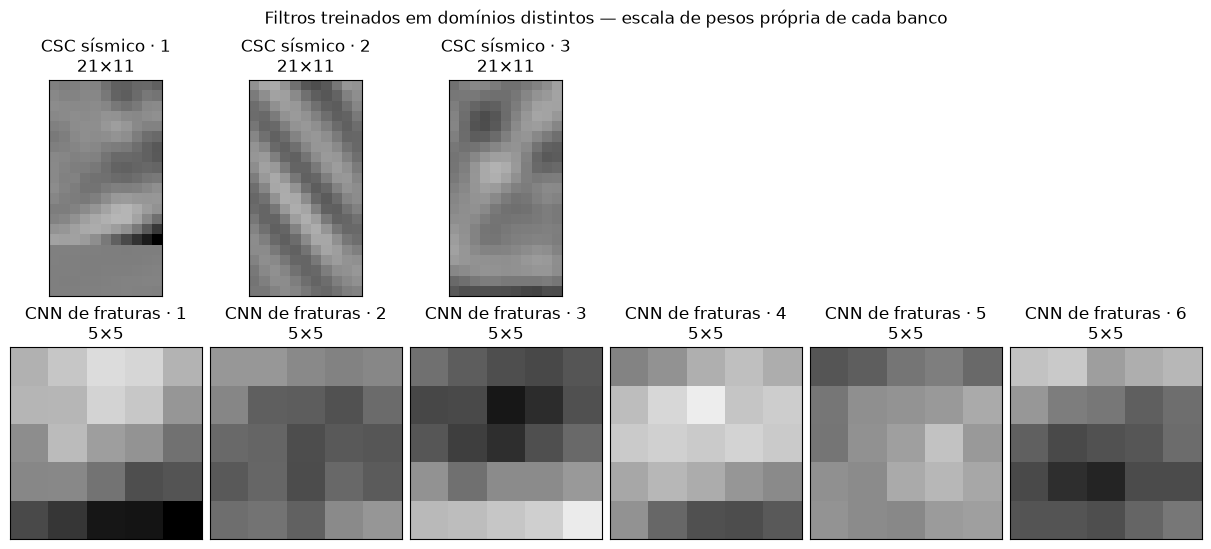

In [67]:
cnn_path = ROOT / "cnn_reference.npz"
if cnn_path.exists():
    with np.load(cnn_path, allow_pickle=False) as cnn:
        provenance = json.loads(str(cnn["metadata_json"].item()))
    display(pd.Series({"Checkpoint": provenance["source_checkpoint"],
                       "SHA-256": provenance["checkpoint_sha256"],
                       "Época selecionada": provenance["selected_epoch"],
                       "Domínio": provenance["training_domain"]}).to_frame("Origem"))
    show(plot_cnn_comparison(reference_training.filters, cnn_path), "csc_cnn_filters")
else:
    display(Markdown("Os pesos opcionais da CNN não estão presentes. A comparação conceitual abaixo continua aplicável; a exportação está documentada no README."))

### Semelhanças e diferenças

A semelhança mais imediata é o uso de **padrões locais com pesos compartilhados espacialmente**. Um mesmo filtro pode participar da representação de estruturas em posições diferentes, sem aprender um conjunto independente de pesos para cada posição. Nas figuras, os dois bancos apresentam pesos positivos e negativos e variações de contraste. Entretanto, a interpretação desses padrões depende de como cada modelo usa seus filtros e de qual erro foi minimizado no treinamento.

**Papel dos filtros e dos mapas.** No CSC, os filtros compõem um modelo de síntese:

$$
\widehat{x}=M\left(\sum_{k=1}^{K}d_k*z_k\right).
$$

Um coeficiente não nulo em $z_k$ introduz uma cópia deslocada e escalada de $d_k$ na reconstrução. Assim, o filtro descreve um padrão disponível e seu mapa descreve onde, com qual amplitude e com qual polaridade esse padrão participa. As contribuições dos filtros precisam explicar conjuntamente a imagem, como mostrado na decomposição do treinamento. Para o CSC de referência, os três filtros são componentes de uma única representação convolucional do CSG.

Na primeira camada da CNN, cada kernel transforma a entrada em um mapa de características. De forma geral, uma camada calcula

$$
a_j^{(\ell)}=\sigma\left(\sum_c W_{j,c}^{(\ell)}*a_c^{(\ell-1)}+b_j^{(\ell)}\right).
$$

Na arquitetura do exercício 04, essas respostas passam por sigmoides, pooling médio, outra camada convolucional e uma camada totalmente conectada até produzir escores de classe. Portanto, um kernel pode ser útil por realçar uma diferença entre fratura e fundo, mesmo que essa transformação não preserve a informação necessária para reconstruir o patch. A segunda camada combina os seis canais anteriores; aumentar K no CSC amplia um banco de síntese, enquanto acrescentar camadas na CNN compõe sucessivas transformações.

**O que é aprendido e como uma nova imagem é processada.** O CSC deste laboratório aprende filtros e coeficientes alternadamente, procurando reduzir o erro de reconstrução com penalização L1. Na aplicação a uma nova imagem, os filtros ficam fixos e os coeficientes são estimados novamente por ADMM:

$$
z^\star(x)=\arg\min_z\;
\frac{\lambda_{\mathrm{res}}}{2}\|x-MDz\|_2^2+\beta\|z\|_1.
$$

Aqui, $D$ reúne as convoluções pelos filtros. Essa otimização considera o que os demais filtros já conseguem representar. Por isso, os mapas CSC não são simplesmente as respostas obtidas ao aplicar cada filtro isoladamente à entrada. Mesmo depois do treinamento, a codificação de uma nova imagem requer atualizações iterativas.

Na CNN do exercício 04, os kernels, os vieses e a camada final são aprendidos com patches rotulados, minimizando o erro quadrático entre escores sigmoides e alvos one-hot. A retropropagação calcula os gradientes, e o SGD atualiza os parâmetros. Durante a classificação, esses parâmetros ficam fixos e as ativações são calculadas por propagação direta, sem resolver uma otimização separada dos mapas para cada patch. O custo de inferência do CSC depende também do número de iterações; o da CNN utilizada depende da sequência fixa de camadas e do tamanho da entrada. Isso não permite classificar um dos métodos como sempre mais rápido, pois arquiteturas, dimensões e implementações também influenciam o tempo.

**Esparsidade, sinal dos coeficientes e restrições.** A penalização L1 atua explicitamente nos mapas CSC e favorece uma atividade concentrada em poucos coeficientes. Os filtros em si podem ser densos. Seus coeficientes podem assumir sinais positivos ou negativos, e o solver aplica limiarização suave durante a estimação. Como o ADMM é interrompido com um orçamento finito, alguns valores retornados podem ser pequenos sem serem exatamente zero; a fração ativa do notebook é uma medida com limiar definido.

As sigmoides da CNN usada aqui produzem ativações entre zero e um, sem impor a mesma penalização L1 aos mapas. Pooling médio também não equivale a uma restrição de representação esparsa. No CSC, a projeção limita a norma L2 de uma variável auxiliar de cada filtro, evitando uma troca arbitrária de escala entre filtros e coeficientes. A CNN de referência não impõe essa mesma projeção. Assim, as amplitudes dos kernels não têm uma interpretação diretamente comparável entre os métodos.

| Aspecto | CSC deste laboratório | CNN do exercício 04 |
|---|---|---|
| Função dos filtros | Componentes para sintetizar a imagem | Transformações para extrair características úteis à classificação |
| Critério de aprendizagem | Fidelidade ao dado e penalização L1 dos coeficientes | Erro quadrático dos escores de classe, com rótulos |
| Representação de cada entrada | Coeficientes ajustados por otimização conjunta | Ativações determinadas pelas operações da rede |
| Organização | Um banco de filtros e soma das contribuições | Hierarquia de convoluções, sigmoides, pooling e classificação |
| Restrição de esparsidade dos mapas | Explícita na função objetivo | Não imposta pela mesma penalização |
| Uso após o treinamento | Estimar novos coeficientes mantendo o dicionário | Calcular a saída mantendo todos os parâmetros |

**Leitura da figura e limites da comparação:** No banco CSC de referência, o segundo filtro apresenta faixas diagonais alternadas, enquanto os outros exibem regiões de contraste mais amplas. Nos kernels CNN, as regiões claras e escuras aparecem em suportes de apenas `5 × 5`; por exemplo, o primeiro separa uma região superior mais clara de uma região inferior mais escura. Essas observações são compatíveis com padrões locais de orientação e contraste. A inspeção dos pesos, por si só, não demonstra que um kernel CNN reconhece uma fratura específica: sua contribuição depende das ativações e das camadas posteriores.

Os filtros CSC mostrados têm suporte `21 × 11` e foram aprendidos em um CSG normalizado. Os seis filtros CNN têm suporte `5 × 5` e foram aprendidos em patches de rocha para distinguir fratura e fundo. O tamanho do suporte, a escala espacial, o domínio dos dados, o pré-processamento e o objetivo de aprendizagem influenciam sua aparência. Além disso, cada banco tem sua própria escala de cores: o contraste visual entre bancos não mede diretamente a magnitude relativa dos pesos. Não se espera uma correspondência individual entre seus filtros.

Essas diferenças também delimitam a interpretação dos experimentos: no CSC, uma penalização alta pode remover eventos sísmicos junto com o ruído se eles exigirem coeficientes que o objetivo passa a desencorajar. Na CNN de classificação, o treinamento favorece informação discriminativa e não exige recuperar as amplitudes do patch. A figura permite discutir como os padrões são usados, mas não estabelece uma comparação de qualidade de denoising entre os dois modelos. CNNs também podem ser treinadas para reconstrução, e representações CSC podem alimentar classificadores; as diferenças de supervisão e de tarefa descritas aqui dizem respeito às implementações comparadas.

## 11. Síntese, exportação e limites do experimento

A tabela final reúne todos os experimentos. O caso `matlab_supplied` usa o dicionário fornecido, enquanto os demais usam dicionários treinados nesta execução. As variações de beta reutilizam o mesmo treinamento: seus tempos de treinamento não devem ser somados como se fossem novos ajustes.

,experiment,snr_after_db,snr_gain_db,mse,active_fraction,denoise_seconds,iterations,stop_reason
0,reference,10.0869,3.0114,0.0453,0.1102,0.2033,80,max_iter
1,matlab_supplied,15.1423,8.0668,0.0142,0.0592,0.1954,80,max_iter
2,size_11x7,14.2925,7.2170,0.0172,0.0881,0.2436,80,max_iter
3,size_31x15,11.7060,4.6305,0.0312,0.0907,0.2417,80,max_iter
4,count_1,3.5355,-3.5399,0.2049,0.2564,0.0670,80,max_iter
5,count_6,12.9887,5.9132,0.0232,0.0496,0.2778,80,max_iter
6,count_9,13.4919,6.4164,0.0207,0.0327,0.3645,80,max_iter
7,count_12,15.9245,8.8490,0.0118,0.0176,0.4403,80,max_iter
8,beta_0p1,12.7220,5.6466,0.0247,0.0348,0.4586,80,max_iter
9,beta_0p25,15.2381,8.1626,0.0138,0.0228,0.4644,80,max_iter


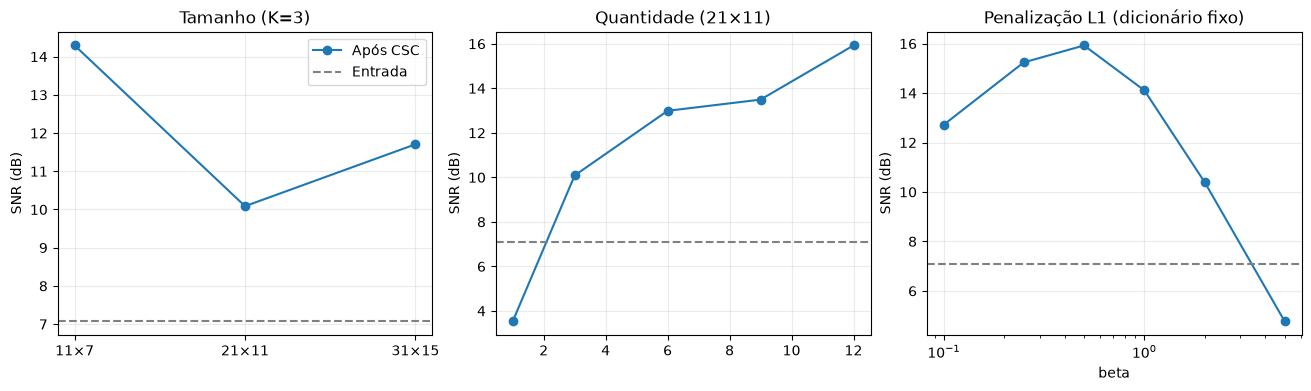

Resumo: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise06/original/results/main/summary.csv
Treinamentos: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise06/original/results/main/training_summary.csv
Figuras: /mnt/c/Users/Lucas Torres/Documents/Acadêmico/Doutorado/Tópicos Especiais em Processamento Inteligente da Informação/exercise06/original/results/main/figures
7 dicionários treinados e 13 reconstruções concluídos.


In [68]:
suite.export_summary()
report(suite.summary)
show(plot_sweeps(suite), "snr_sweeps")
metadata_check = json.loads((OUTPUT / "settings.json").read_text())
assert metadata_check["data_sha256"] == suite.metadata["data_sha256"]
expected_trainings = {size_name(s) for s in SIZES} | {count_name(k) for k in COUNTS}
expected_denoisings = expected_trainings | {"matlab_supplied"} | set(beta_ids)
assert set(suite.trainings) == expected_trainings
assert set(suite.denoisings) == expected_denoisings
assert len(beta_ids) == len(BETAS)
print("Resumo:", OUTPUT / "summary.csv")
print("Treinamentos:", OUTPUT / "training_summary.csv")
print("Figuras:", FIGURES)
print(f"{len(suite.trainings)} dicionários treinados e {len(suite.denoisings)} reconstruções concluídos.")

### Conclusões da execução de referência

1. **Tamanho:** `11 × 7` foi o melhor suporte da série, com **14,29 dB**. A melhora não foi monotônica com o aumento do suporte.
2. **Quantidade:** seis filtros produziram **12,99 dB**, acima dos três filtros de referência. Um filtro piorou a entrada ruidosa, mostrando que a restrição de representação pode retirar sinal útil.
3. **Penalização L1:** beta = 0,25 atingiu **11,78 dB** para o dicionário de referência. Valores altos aumentaram a esparsidade, mas também retiraram estruturas sísmicas.
4. **Comparação CSC/CNN:** ambos aprendem filtros locais compartilhados; o objetivo de síntese esparsa do CSC e a classificação supervisionada da CNN levam a usos e inferências distintos.

O dicionário MATLAB fornecido atingiu **15,14 dB** no mesmo dado ruidoso. As diferenças de solução local, inicialização e histórico de treinamento devem ser consideradas ao avaliar essa comparação. Uma única semente e um único CSG de avaliação não permitem conclusões gerais sobre o melhor tamanho, K ou beta. O experimento usa ruído gaussiano sintético e não avalia remoção de ruído coerente nem preservação de amplitudes físicas.

As saídas numéricas e as figuras ficam em `original/results/main/`, e este notebook conserva também as tabelas e as figuras da execução. O [README](README.md) descreve a instalação, a execução pelo terminal, os formatos de saída e a regeneração opcional dos filtros da CNN.

## Referências

- [Enunciado e pacote MATLAB — Zhaolun Liu](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Sparse/Chapter.Sparse2/lab.html).
- [Resumo teórico — Zhaolun Liu, Kai Lu e Xiaodan Ge](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Sparse/Chapter.Sparse2/CSCdenoising.pdf).
- [Slides do laboratório](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Sparse/Chapter.Sparse2/csc.pptx).
- F. Heide, W. Heidrich e G. Wetzstein. *Fast and Flexible Convolutional Sparse Coding*. CVPR, 2015. Núcleo atribuído a esses autores nos fontes MATLAB, com adaptações de Zhaolun Liu.
- [Exercício 04 — CNN para fraturas](../exercise04/README.md), origem dos filtros da comparação visual.